# Automotive Stock Analysis: Tesla, Ford, and GM (2021, 2026)

Comparative analysis of historical opening prices and trading volume across **Tesla**, **Ford**, and **GM** from `2017-01-01` to `2026-09-01`.

____
## 1. Imports and Configuration

In [1]:
import datetime
import pandas as pd
from pandas.plotting import scatter_matrix
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

%matplotlib inline

----
## 2. Data Loading and Inspection

In [2]:
start = datetime.datetime(2021, 1, 1)
end = datetime.datetime(2026, 9, 1)

----
### 2.1 Tesla

In [3]:
df_tesla = yf.download("TSLA", start=start, end=end, auto_adjust=True, multi_level_index=False)
df_tesla.head()

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2021-01-04,243.256668,248.163330,239.063339,239.820007,145914600
2021-01-05,245.036667,246.946671,239.733337,241.220001,96735600
2021-01-06,251.993332,258.000000,249.699997,252.830002,134100000
2021-01-07,272.013336,272.329987,258.399994,259.209991,154496700
2021-01-08,293.339996,294.829987,279.463318,285.333344,225166500


### 2.2 Ford

In [4]:
df_ford = yf.download("F", start=start, end=end, auto_adjust=True, multi_level_index=False)
df_ford.head()

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2021-01-04,6.173162,6.405018,6.107953,6.383282,85043100
2021-01-05,6.267355,6.318074,6.129691,6.136937,70127800
2021-01-06,6.405019,6.477474,6.289091,6.368792,72590200
2021-01-07,6.564422,6.578913,6.434003,6.477476,77117100
2021-01-08,6.520948,6.622386,6.441248,6.593404,59162200


### 2.3 General Motors (GM)

In [5]:
df_gm = yf.download("GM", start=start, end=end, auto_adjust=True, multi_level_index=False)
df_gm.head()

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2021-01-04,38.828384,40.371552,38.473745,40.208611,15768100
2021-01-05,39.930653,40.103181,38.377901,38.397072,18045800
2021-01-06,41.195858,42.029742,40.122351,40.179858,22694900
2021-01-07,41.521729,42.154331,41.176672,42.154331,13625700
2021-01-08,41.272537,41.684688,40.563254,41.512159,18426200


## 3. Exploratory Data Visualization

### 3.1 Opening Price Comparison

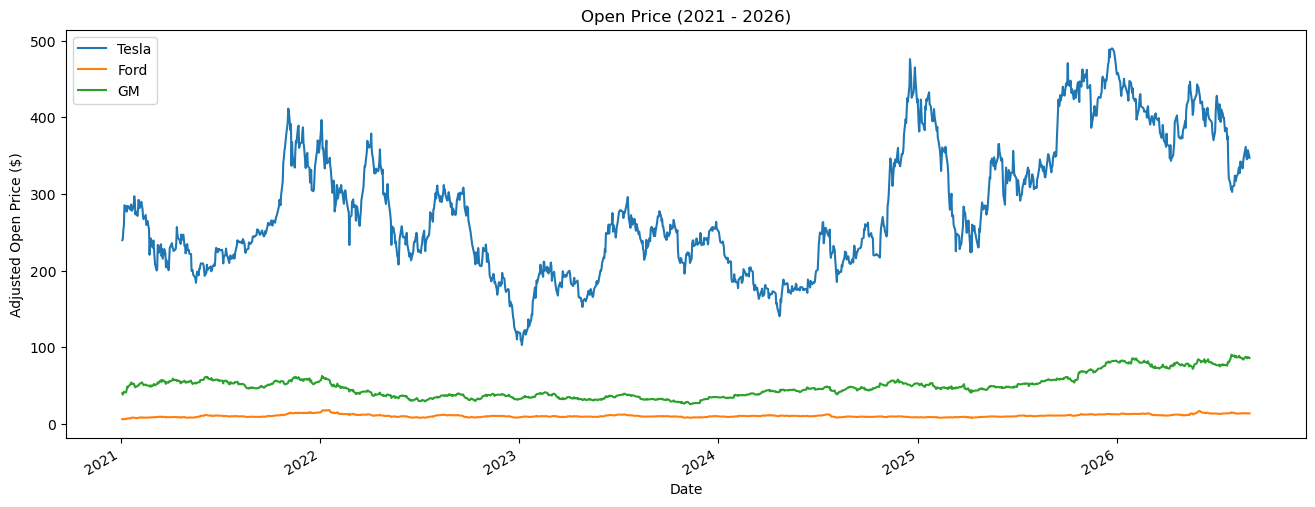

In [6]:
df_tesla['Open'].plot(label = "Tesla", figsize=(16, 6), title= "Open Price (2021 - 2026)")
df_ford["Open"].plot(label = "Ford")
df_gm["Open"].plot(label = "GM")

plt.ylabel("Adjusted Open Price ($)")
plt.legend()
plt.show()

### 3.2 Daily Traded Volume

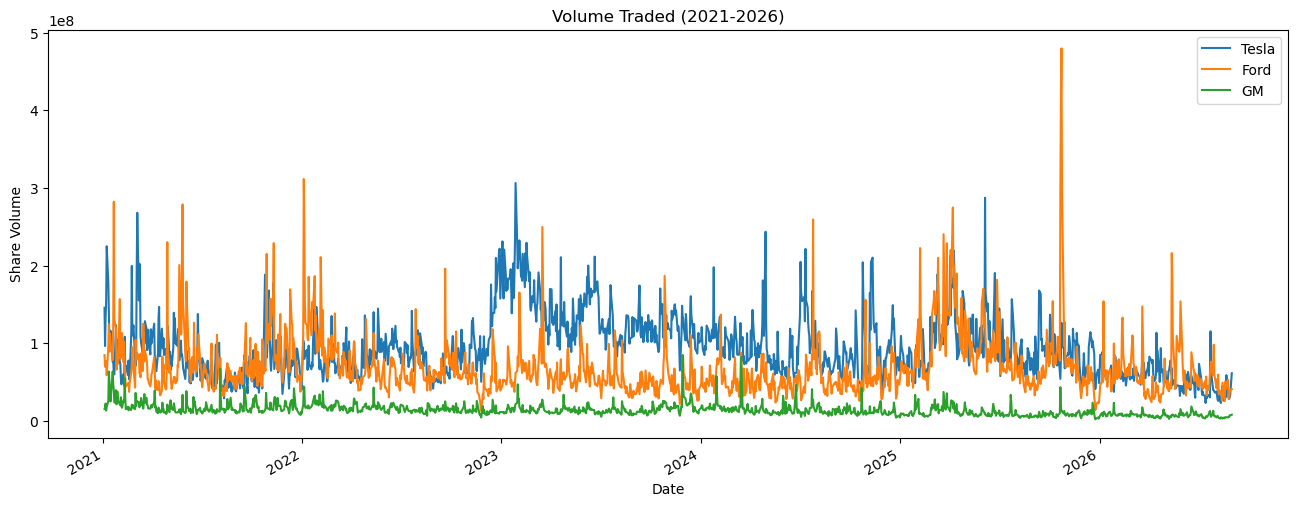

In [7]:
df_tesla['Volume'].plot(label = "Tesla", figsize=(16, 6), title= "Volume Traded (2021-2026)")
df_ford["Volume"].plot(label = "Ford")
df_gm["Volume"].plot(label = "GM")

plt.ylabel("Share Volume")
plt.legend()
plt.show()

#### 3.2.1 Highest Volume Trading Day for each Automaker

In [8]:
for name, df in [("Tesla", df_tesla), ("Ford", df_ford), ("GM", df_gm)]:
    peak_date = df["Volume"].idxmax()
    peak_vol = df.loc[peak_date, "Volume"]
    print(f"{name} Peak Volume: {peak_vol:,.0f} shares on {peak_date.strftime('%Y-%m-%d')}")

Tesla Peak Volume: 306,590,600 shares on 2023-01-27
Ford Peak Volume: 479,840,300 shares on 2025-10-23
GM Peak Volume: 85,193,700 shares on 2023-11-29


### 3.3 Total Dollar Volume Traded (Open x Volume)

In [9]:
df_tesla["Total Traded"] = df_tesla["Open"] * df_tesla["Volume"]
df_ford["Total Traded"] = df_ford["Open"] * df_ford["Volume"]
df_gm["Total Traded"] = df_gm["Open"] * df_gm["Volume"]

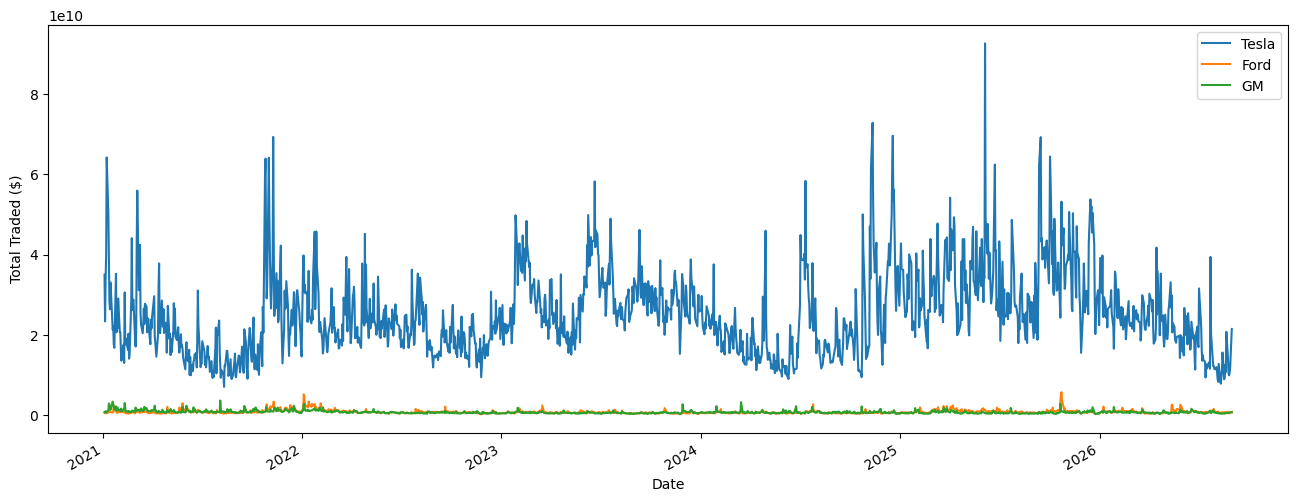

In [10]:
df_tesla["Total Traded"].plot(label = "Tesla", figsize=(16, 6))
df_ford["Total Traded"].plot(label = "Ford")
df_gm["Total Traded"].plot(label = "GM")

plt.legend()
plt.ylabel("Total Traded ($)")
plt.show()

In [11]:
for name, df in [("Tesla", df_tesla), ("Ford", df_ford), ("GM", df_gm)]:
    peak_date = df["Total Traded"].idxmax()
    peak_traded = df.loc[peak_date, "Total Traded"]
    print(f"{name} Peak Dollar Volume Traded: ${peak_traded:,.0f} on {peak_date.strftime('%Y-%m-%d')}")

Tesla Peak Dollar Volume Traded: $92,715,807,694 on 2025-06-05
Ford Peak Dollar Volume Traded: $5,648,564,488 on 2025-10-23
GM Peak Dollar Volume Traded: $3,582,120,873 on 2021-08-04


### 3.4 Moving Averages (50-Day & 200-Day SMA)

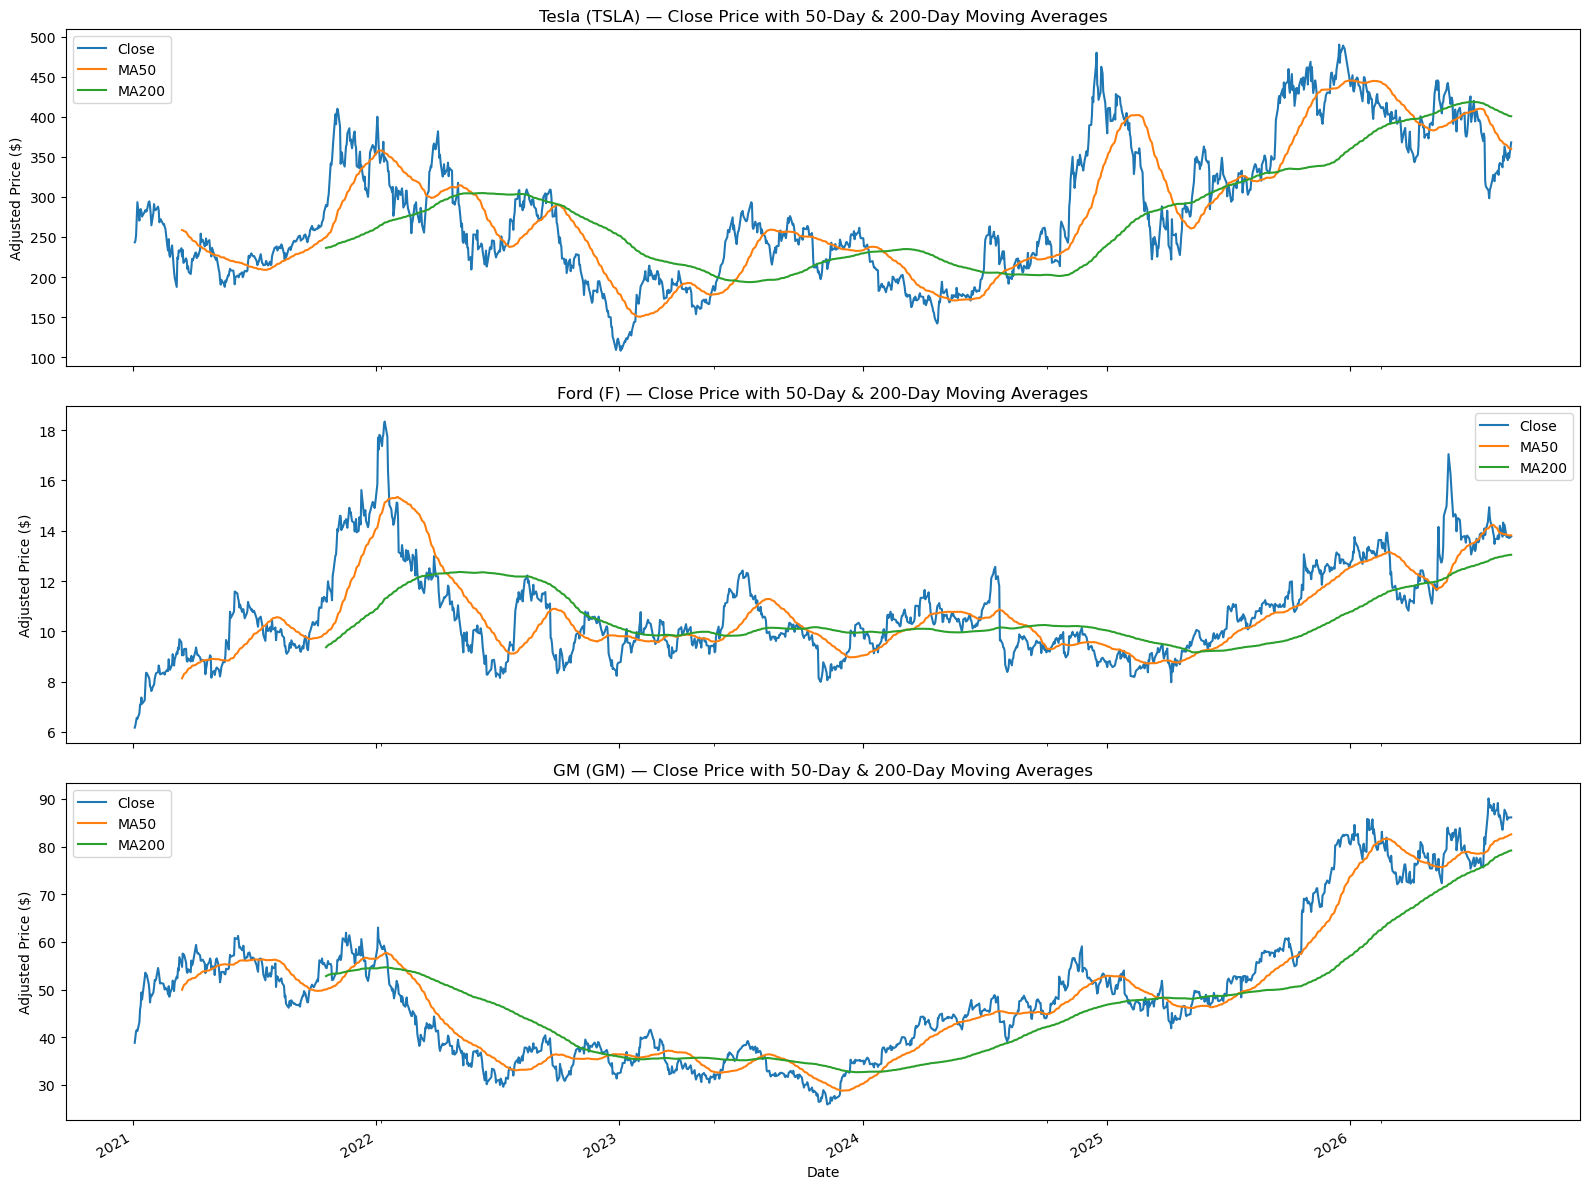

In [12]:
for df in (df_tesla, df_ford, df_gm):
    df["MA50"] = df["Close"].rolling(50).mean()
    df["MA200"] = df["Close"].rolling(200).mean()

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)
for ax, (name, df) in zip(axes, [("Tesla (TSLA)", df_tesla), ("Ford (F)", df_ford), ("GM (GM)", df_gm)]):
    df[["Close", "MA50", "MA200"]].plot(ax=ax, title=f"{name} — Close Price with 50-Day & 200-Day Moving Averages")
    ax.set_ylabel("Adjusted Price ($)")

plt.tight_layout()
plt.show()

----
## 4. Return and Volatility Analysis

### 4.1 Daily Returns & Cumulative Growth ($1 Invested)

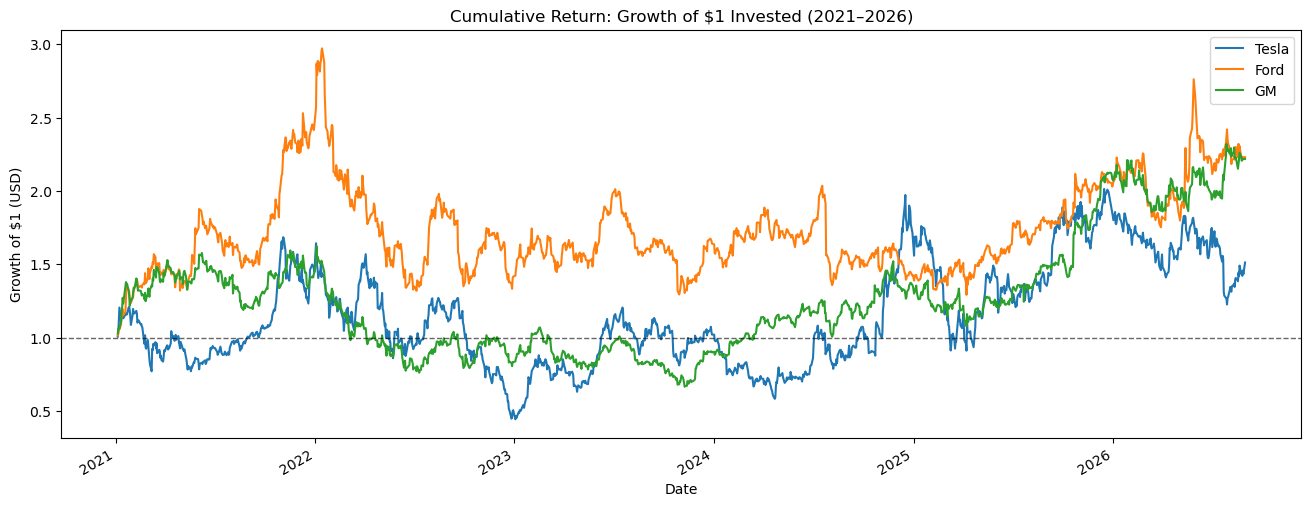

In [13]:
for df in (df_tesla, df_ford, df_gm):
    df["Returns"] = df["Close"].pct_change()
    df["Cumulative Return"] = (1 + df["Returns"]).cumprod()

df_tesla["Cumulative Return"].plot(label="Tesla", figsize=(16, 6), title="Cumulative Return: Growth of $1 Invested (2021–2026)")
df_ford["Cumulative Return"].plot(label="Ford")
df_gm["Cumulative Return"].plot(label="GM")
plt.axhline(1.0, color="black", linestyle="--", linewidth=1, alpha=0.6)
plt.ylabel("Growth of $1 (USD)")
plt.legend()
plt.show()

### 4.2 Summary Quantitative Statistics

In [14]:
summary_rows = []
for ticker, df in [("TSLA", df_tesla), ("F", df_ford), ("GM", df_gm)]:
    daily_ret = df["Returns"].dropna()
    final_wealth = df["Cumulative Return"].dropna().iloc[-1]
    summary_rows.append({
        "Ticker": ticker,
        "Daily Mean Return (%)": round(daily_ret.mean() * 100, 4),
        "Daily Volatility / Std Dev (%)": round(daily_ret.std() * 100, 2),
        "Annualized Volatility (%)": round(daily_ret.std() * np.sqrt(252) * 100, 2),
        "Sharpe Ratio (Rf=0)": round((daily_ret.mean() / daily_ret.std()) * np.sqrt(252), 2),
        "Value of $1 Invested ($)": round(final_wealth, 2),
        "Total Return (%)": round((final_wealth - 1) * 100, 2),
    })

summary_df = pd.DataFrame(summary_rows).set_index("Ticker")
summary_df

,Daily Mean Return (%),Daily Volatility / Std Dev (%),Annualized Volatility (%),Sharpe Ratio (Rf=0),Value of $1 Invested ($),Total Return (%)
Ticker,,,,,,
TSLA,0.0984,3.73,59.24,0.42,1.51,51.26
F,0.0878,2.50,39.62,0.56,2.23,123.11
GM,0.0829,2.32,36.85,0.57,2.22,121.85


### 4.3 Return Distributions: Histograms, KDE Plots, and Box Plots

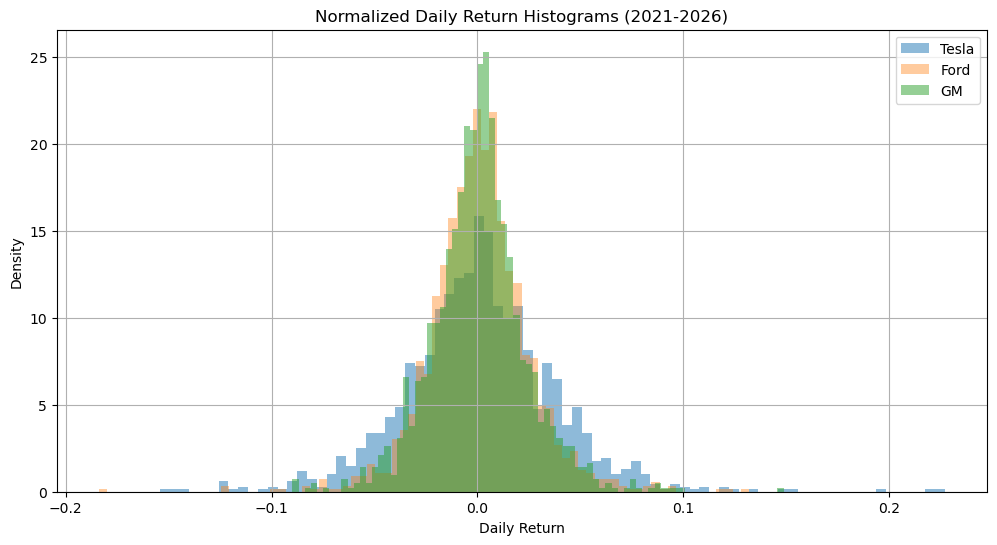

In [15]:
df_tesla["Returns"].hist(bins=80, label="Tesla", figsize=(12, 6), alpha=0.5, density=True)
df_ford["Returns"].hist(bins=80, label="Ford", alpha=0.4, density=True)
df_gm["Returns"].hist(bins=80, label="GM", alpha=0.5, density=True)
plt.title("Normalized Daily Return Histograms (2021-2026)")
plt.xlabel("Daily Return")
plt.ylabel("Density")
plt.legend()
plt.show()

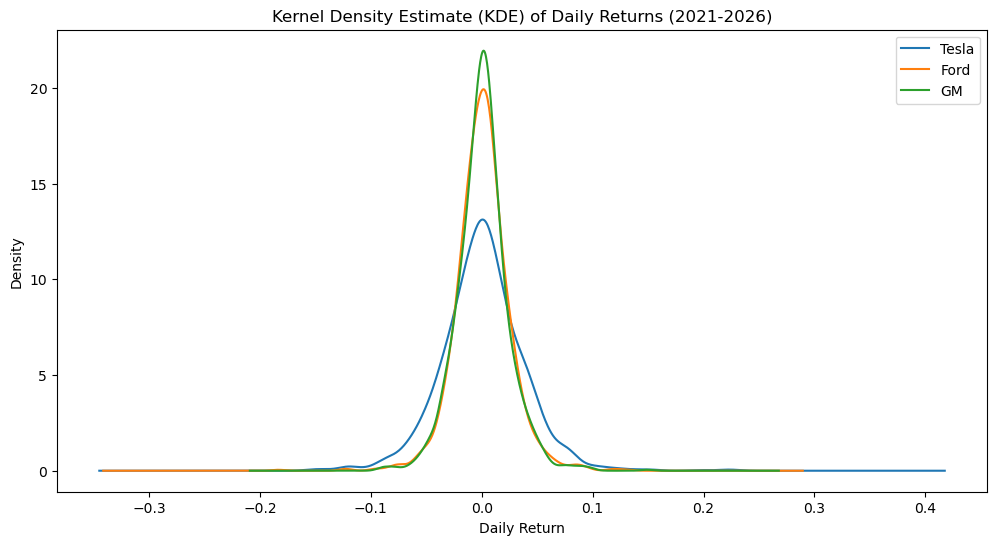

In [16]:
df_tesla["Returns"].plot(kind="kde", label="Tesla", figsize=(12, 6), title="Kernel Density Estimate (KDE) of Daily Returns (2021-2026)")
df_ford["Returns"].plot(kind="kde", label="Ford")
df_gm["Returns"].plot(kind="kde", label="GM")
plt.xlabel("Daily Return")
plt.legend()
plt.show()

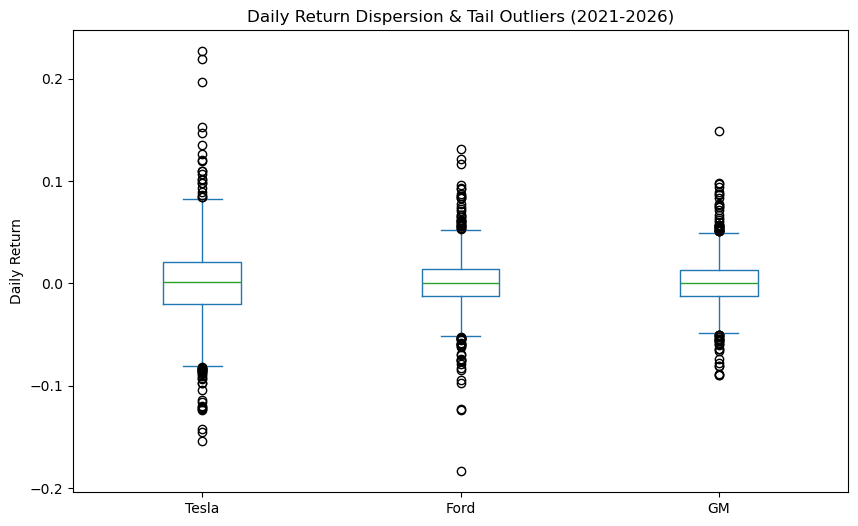

In [17]:
box_df = pd.concat(
    [df_tesla["Returns"], df_ford["Returns"], df_gm["Returns"]],
    axis=1,
    keys=["Tesla", "Ford", "GM"],
)
box_df.plot(kind="box", figsize=(10, 6), title="Daily Return Dispersion & Tail Outliers (2021-2026)")
plt.ylabel("Daily Return")
plt.show()

----
## 5. Daily Return Scatter Matrix & Correlation Matrix

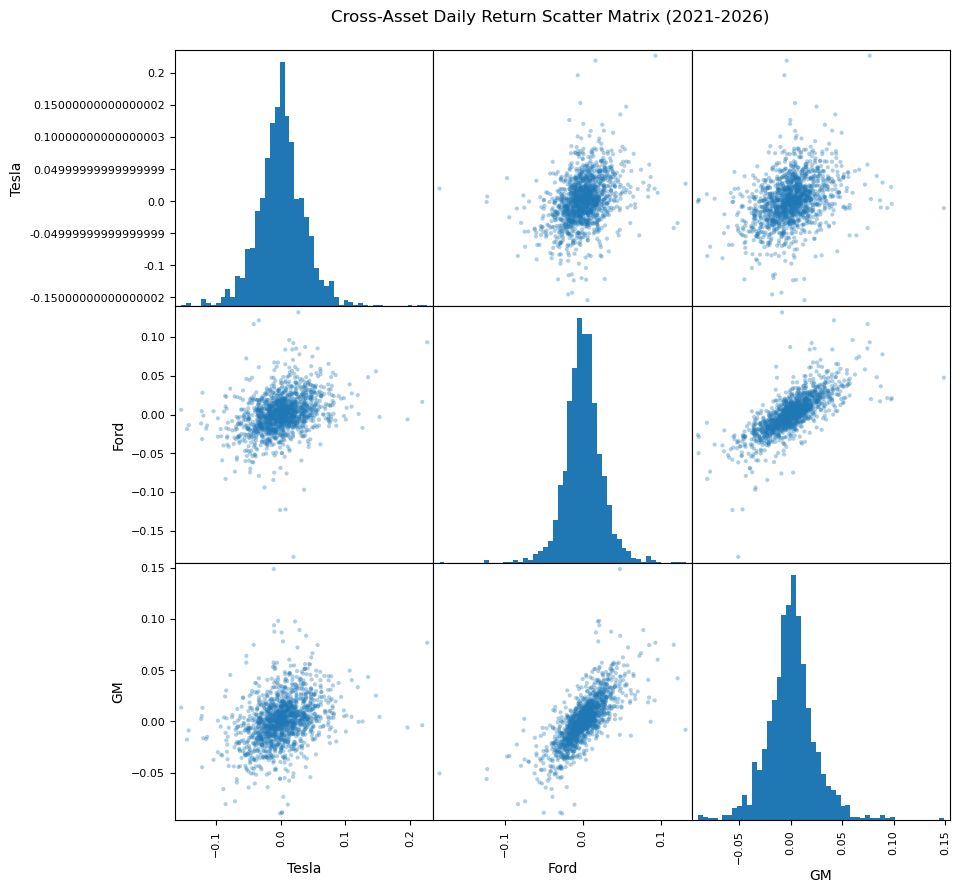

,Tesla,Ford,GM
Tesla,1.000000,0.332555,0.337127
Ford,0.332555,1.000000,0.736347
GM,0.337127,0.736347,1.000000


In [18]:
scatter_matrix(box_df, figsize=(10, 10), alpha=0.35, hist_kwds={"bins": 50})
plt.suptitle("Cross-Asset Daily Return Scatter Matrix (2021-2026)", y=0.92)
plt.show()

box_df.corr()